# Проект. Исследование стартапов

## Введение

Автор: Дегтярёва Александра 

**Цель:** Провести исследовательский анализ динамики и структуры финансирования стартапов

**Задачи:**
1. Провести предобработку данных, убрать дубликаты и пропуски, проверить корректность числовых и временных значений
2. Выделить группы компаний по срокам финансирования и сравнить их по количеству и объёму инвестиций
3. Классифицировать сегменты рынка на массовые, средние и нишевые и учесть это в дальнейшем анализе
4. Определить типичные и аномальные значения объёмов финансирования, исключить выбросы и ограничить период исследования
5. Сравнить популярность и объёмы разных типов финансирования
6. Проанализировать динамику раундов и объёмов инвестиций по годам, а также изменения в массовых сегментах рынка
7. Рассчитать долю возврата средств для разных типов финансирования и оценить её устойчивость
8. Подвести итоговые выводы и дать рекомендации

## Шаг 1. Знакомство с данными: загрузка и предобработка

Датасет получен из базы данных стартапов.

Название основного датасета — `cb_investments.zip`. Внутри архива один файл — `cb_investments.csv`.

Описание данных:
* `name` — название компании.
* `homepage_url` — ссылка на сайт компании.
* `category_list` — категории, в которых работает компания. Указываются через `|`.
* `market` — основной рынок или отрасль компании (сегмент)
* `funding_total_usd` — общий объём привлечённых инвестиций в долларах США.
* `status` — текущий статус компании, например `operating`, `closed` и так далее.
* `country_code` — код страны, например USA.
* `state_code` — код штата или региона, например, CA.
* `region` — регион, например, SF Bay Area.
* `city` — город, в котором расположена компания.
* `funding_rounds` — общее число раундов финансирования.
* `participants` — число участников в раундах финансирования.
* `founded_at` — дата основания компании.
* `founded_month` — месяц основания в формате `YYYY-MM`.
* `founded_quarter` — квартал основания в формате `YYYY-QN`.
* `founded_year` — год основания.
* `first_funding_at` — дата первого финансирования.
* `mid_funding_at` — дата среднего по времени раунда финансирования.
* `last_funding_at` — дата последнего финансирования.
* `seed` — сумма инвестиций на посевной стадии.
* `venture` — сумма венчурных инвестиций.
* `equity_crowdfunding` — сумма, привлечённая через долевой краудфандинг.
* `undisclosed` — сумма финансирования нераскрытого типа.
* `convertible_note` — сумма инвестиций через конвертируемые займы.
* `debt_financing` — сумма долгового финансирования.
* `angel` — сумма инвестиций от бизнес-ангелов.
* `grant` — сумма полученных грантов.
* `private_equity` — сумма инвестиций в виде прямых (частных) вложений.
* `post_ipo_equity` — сумма финансирования после IPO.
* `post_ipo_debt` — сумма долгового финансирования после IPO.
* `secondary_market` — сумма сделок на вторичном рынке.
* `product_crowdfunding` — сумма, привлечённая через продуктовый краудфандинг.
* `round_A` — `round_H` — сумма инвестиций в соответствующем раунде.

Название дополнительного датасета — `cb_returns.csv`. Он содержит суммы возвратов по типам финансирования в миллионах долларов по годам.

Описание данных:
* `year` — год возврата средств.
* `seed` — сумма возвратов от посевных инвестиций.
* `venture` — сумма возвратов от венчурных инвестиций.
* `equity_crowdfunding` — сумма, возвращённая по долевому краудфандингу.
* `undisclosed` — сумма возвратов нераскрытого типа.
* `convertible_note` — сумма возвратов через конвертируемые займы.
* `debt_financing` — сумма возвратов от долгового финансирования.
* `angel` — сумма возвратов бизнес-ангелам.
* `grant` — сумма возвратов по грантам.
* `private_equity` — сумма возвратов прямых (частных) вложений.
* `post_ipo_equity` — сумма возвратов от IPO.
* `post_ipo_debt` — сумма возвратов от долгового IPO.
* `secondary_market` — сумма возвратов от сделок на вторичном рынке.
* `product_crowdfunding` — сумма возвратов по продуктовому краудфандингу.

Файлы находятся в папке `datasets`, если вы выполняете работу на платформе. В случае, если вы делаете работу локально, доступ к файлам в папке можно получить по адресу `https://code.s3.yandex.net/datasets/` + имя файла.

### 1.1. Вывод общей информации

Загрузите необходимые для работы библиотеки.

Совет: если вы неоднократно используете какой-либо код, вынесите его в начало проекта в виде функций.

In [1]:
# Импортируем библиотеки
import pandas as pd

# Загружаем библиотеки для визуализации данных
import matplotlib.pyplot as plt
import seaborn as sns


Загрузите все данные по проекту.

Совет: данные из zip-архива можно загрузить следующим кодом:

`df = pd.read_csv("https://code.s3.yandex.net/datasets/cb_investments.zip", sep=';', low_memory=False)`

In [2]:
df_investments = pd.read_csv("https://code.s3.yandex.net/datasets/cb_investments.zip", sep=';', low_memory=False)

In [3]:
df_returns = pd.read_csv('https://code.s3.yandex.net/datasets/cb_returns.csv')

Выведите информацию, которая необходима для принятия решений о предобработке.

In [4]:
df_investments.info()

# Запоминаем исходное количество строк
initial_rows = len(df_investments)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54294 entries, 0 to 54293
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   name                  49437 non-null  object 
 1   homepage_url          45989 non-null  object 
 2   category_list         45477 non-null  object 
 3    market               45477 non-null  object 
 4    funding_total_usd    49438 non-null  object 
 5   status                48124 non-null  object 
 6   country_code          44165 non-null  object 
 7   state_code            30161 non-null  object 
 8   region                44165 non-null  object 
 9   city                  43322 non-null  object 
 10  funding_rounds        49438 non-null  float64
 11  participants          30473 non-null  float64
 12  founded_at            38554 non-null  object 
 13  founded_month         38482 non-null  object 
 14  founded_quarter       38482 non-null  object 
 15  founded_year       

In [5]:
# Смотрим кол-во пропусков в относительных значениях
round(df_investments.isna().sum()/len(df_investments) * 100, 2)

name                     8.95
homepage_url            15.30
category_list           16.24
 market                 16.24
 funding_total_usd       8.94
status                  11.36
country_code            18.66
state_code              44.45
region                  18.66
city                    20.21
funding_rounds           8.94
participants            43.87
founded_at              28.99
founded_month           29.12
founded_quarter         29.12
founded_year            28.99
first_funding_at         8.94
mid_funding_at          44.21
last_funding_at          8.94
seed                     8.94
venture                  8.94
equity_crowdfunding      8.94
undisclosed              8.94
convertible_note         8.94
debt_financing           8.94
angel                    8.94
grant                    8.94
private_equity           8.94
post_ipo_equity          8.94
post_ipo_debt            8.94
secondary_market         8.94
product_crowdfunding     8.94
round_A                  8.94
round_B   

In [6]:
print(f'Размер датасета: {df_investments.shape[0]} строк, {df_investments.shape[1]} столбцов.')
print('Первые 3 строчки:')
display(df_investments.head(3))
print('Рандомные 3 строчки:')
display(df_investments.sample(3, random_state=42))
print('Последние 3 строчки:')
display(df_investments.tail(3))

Размер датасета: 54294 строк, 40 столбцов.
Первые 3 строчки:


,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
0,Harvard University,http://harvard.edu,|Education|,Education,"9,00,00,000",operating,USA,MA,Boston,Cambridge,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,University of New Brunswick,http://www.unb.ca,NaN,NaN,"20,00,000",operating,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,DuPont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,Business Services,"90,00,000",operating,USA,DE,"Wilmington, Delaware",Wilmington,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Рандомные 3 строчки:


,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
30166,Appbyme,http://www.appbyme.net,|Mobile|,Mobile,"10,00,000",operating,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
12481,Totally Interactive Weather,http://totallyinteractiveweather.com,|News|,News,"3,00,000",operating,USA,MN,MN - Other,Beaver Creek,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
45753,RotaPost,http://www.rotapost.ru/,NaN,NaN,-,operating,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Последние 3 строчки:


,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
54291,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
54292,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
54293,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
df_returns.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   year                  15 non-null     int64  
 1   seed                  15 non-null     float64
 2   venture               15 non-null     float64
 3   equity_crowdfunding   15 non-null     float64
 4   undisclosed           15 non-null     float64
 5   convertible_note      15 non-null     float64
 6   debt_financing        15 non-null     float64
 7   angel                 15 non-null     float64
 8   grant                 15 non-null     float64
 9   private_equity        15 non-null     float64
 10  post_ipo_equity       15 non-null     float64
 11  post_ipo_debt         15 non-null     float64
 12  secondary_market      15 non-null     float64
 13  product_crowdfunding  15 non-null     float64
dtypes: float64(13), int64(1)
memory usage: 1.8 KB


In [8]:
# Первичный осмотр данных
print(f'Размер датасета: {df_returns.shape[0]} строк, {df_returns.shape[1]} столбцов.')

print('Первые 3 строчки:')
display(df_returns.head(3))

print('Рандомные 3 строчки:')
display(df_returns.sample(3, random_state=42))

print('Последние 3 строчки:')
display(df_returns.tail(3))

Размер датасета: 15 строк, 14 столбцов.
Первые 3 строчки:


,year,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
0,2000,16.70,55.40,0.0,78.21,0.00,8.66,6.43,0.0,0.00,0.94,0.0,0.20,0.0
1,2001,2.88,23.49,0.0,21.50,0.01,4.49,1.18,0.0,0.00,0.46,0.0,0.46,0.0
2,2002,6.59,209.42,0.0,25.77,0.02,3.42,3.41,0.0,1.51,0.34,0.0,0.06,0.0


Рандомные 3 строчки:


,year,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
9,2009,160.21,2501.29,0.18,37.50,2.25,394.10,97.21,0.0,203.70,76.76,0.00,0.12,0.02
11,2011,317.29,3919.38,0.30,59.36,3.96,572.92,172.17,0.0,666.03,129.01,3.04,0.16,0.26
0,2000,16.70,55.40,0.00,78.21,0.00,8.66,6.43,0.0,0.00,0.94,0.00,0.20,0.00


Последние 3 строчки:


,year,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
12,2012,373.31,4727.74,0.44,71.04,4.79,694.97,193.03,0.0,762.40,160.88,20.34,0.34,0.28
13,2013,442.97,5749.29,1.14,84.40,6.00,848.65,225.87,0.0,988.53,219.93,30.45,0.81,0.34
14,2014,530.75,7272.01,1.15,105.72,7.87,1017.75,293.98,0.0,384.01,262.70,37.20,1.03,0.72


**Выводы:**

Датасет `df_investments` содержит 54294 строк, 40 столбцов (информация о компаниях и состоявшемся финансировании)

- Данные соответствуют описанию, названия столбцов приведены к названиям удобным для анализа, есть лишние пробелы в названии некоторых столбцов
- Во всех стобцах содержатся пропуски, где-то больше, где-то меньше, нужно учитывать при обработке данных
- Можно оптимизировать кол-во используемой памяти с помощью уменьшения разрядности и смены типа данных

Датасет `df_returns` содержит 15 строк, 14 столбцов (информация об объёмах возвратов по годам и типам финансирования в миллионах долларов)
- Данные соответствуют описанию, названия столбцов приведены к названиям удобным для анализа
- Не содержит пропусков (но есть нулевые значения)
- Можно оптимизировать кол-во используемой памяти с помощью уменьшения разрядности

Сделайте вывод о полученных данных: каков их объём, соответствуют ли данные описанию, есть ли пропущенные значения, используются ли верные типы данных. Отметьте другие особенности данных, которые вы обнаружите на этой стадии и на которые стоит обратить внимание при предобработке.

### 1.2. Предобработка данных

In [9]:
# Убираем лишние пробелы в названиях столбцов 
df_investments.columns = df_investments.columns.str.replace(' ', '')

Уберите в столбце `funding_total_usd` выделение разрядов и приведите его к числовому типу.

In [10]:
# Избавляемся от выделения разрядов
df_investments['funding_total_usd'] = df_investments['funding_total_usd'].str.replace(',', '')

# Меняем тип данных учитывая пропуски
df_investments['funding_total_usd'] = pd.to_numeric(df_investments['funding_total_usd'], errors='coerce').astype('Int64')

Обработайте типы данных в столбцах, которые хранят значения даты и времени, если это необходимо.

In [11]:
columns = [
    'founded_at',         # дата основания компании
    'founded_month',      # месяц основания в формате YYYY-MM
    'founded_quarter',    # квартал основания в формате YYYY-QN
    'founded_year',       # год основания
    'first_funding_at',   # дата первого финансирования
    'mid_funding_at',     # дата среднего по времени раунда финансирования
    'last_funding_at'     # дата последнего финансирования
]

for column in columns:
    df_investments[column] = pd.to_datetime(df_investments[column], errors='coerce')


В датасете `cb_returns` сделайте столбец `year` индексом всего датасета, если не делали это при загрузке.

In [12]:
df_returns = df_returns.set_index('year')

Обработайте текстовые данные, если это необходимо. Пропуски в текстовых столбцах заполните заглушками там, где это понадобится.

In [13]:
# Обрабатываем тектовые столбцы (ставим заглушки)
object_columns = [
    'name', 'homepage_url', 'category_list', 'market', 'status', 'country_code',
    'state_code', 'region', 'city'
]

for col in object_columns:
    df_investments[col] = df_investments[col].fillna('Unknown')
    
# Меняем тип данных для оптимизации импользуемой памяти 
category_columns = [
    'market',
    'status',
    'country_code',
    'state_code', 
    'region',         
    'city'     
]

for col in category_columns:
    df_investments[col] = df_investments[col].astype('category')

In [14]:
# Оптимизируем память для числовых столбцов 
numeric_columns = [
    'funding_total_usd', 'funding_rounds', 'participants', 'seed', 'venture',
    'equity_crowdfunding', 'undisclosed', 'convertible_note', 'debt_financing',
    'angel', 'grant', 'private_equity', 'post_ipo_equity', 'post_ipo_debt',
    'secondary_market', 'product_crowdfunding',
    'round_A', 'round_B', 'round_C', 'round_D', 'round_E', 'round_F', 'round_G', 'round_H'
]

for col in numeric_columns:
    df_investments[col] = pd.to_numeric(df_investments[col], downcast='float')

In [15]:
df_investments.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54294 entries, 0 to 54293
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   name                  54294 non-null  object        
 1   homepage_url          54294 non-null  object        
 2   category_list         54294 non-null  object        
 3   market                54294 non-null  category      
 4   funding_total_usd     40907 non-null  float32       
 5   status                54294 non-null  category      
 6   country_code          54294 non-null  category      
 7   state_code            54294 non-null  category      
 8   region                54294 non-null  category      
 9   city                  54294 non-null  category      
 10  funding_rounds        49438 non-null  float32       
 11  participants          30473 non-null  float32       
 12  founded_at            38553 non-null  datetime64[ns]
 13  founded_month   

Видим что **существенно** сократили используюмую память

Обработайте полные дубликаты в данных и пропуски в `funding_total_usd`. избавьтесь от тех строк, которые не несут какой-либо информации либо не содержат данных о финансировании.

In [16]:
# Удаляем полные дубликаты
df_investments = df_investments.drop_duplicates()

# Удаляем строки не содержащие информацию о финансировании
df_investments = df_investments.dropna(subset=['funding_total_usd'])

Заполните пропуски в значениях `mid_funding_at` на основании значений в столбцах `first_funding_at` и `last_funding_at`. В качестве нового значения вместо пропусков возьмите приблизительно середину интервала между этими двумя датами.

Оцените размер оставшихся пропусков в столбце.

In [17]:
# Заполняем пропуски через функцию
def fill_mid_funding(row):
    if pd.isna(row['mid_funding_at']):
        first = row['first_funding_at']
        last = row['last_funding_at']
        if pd.notna(first) and pd.notna(last):
            # Середина интервала
            return first + (last - first) / 2
    return row['mid_funding_at']

df_investments['mid_funding_at'] = df_investments.apply(fill_mid_funding, axis=1)

In [18]:
round(df_investments.isna().sum() / len(df_investments) * 100, 2)

name                     0.00
homepage_url             0.00
category_list            0.00
market                   0.00
funding_total_usd        0.00
status                   0.00
country_code             0.00
state_code               0.00
region                   0.00
city                     0.00
funding_rounds           0.00
participants            33.19
founded_at              21.28
founded_month           21.44
founded_quarter         21.44
founded_year            21.28
first_funding_at         0.00
mid_funding_at           0.00
last_funding_at          0.00
seed                     0.00
venture                  0.00
equity_crowdfunding      0.00
undisclosed              0.00
convertible_note         0.00
debt_financing           0.00
angel                    0.00
grant                    0.00
private_equity           0.00
post_ipo_equity          0.00
post_ipo_debt            0.00
secondary_market         0.00
product_crowdfunding     0.00
round_A                  0.00
round_B   

In [19]:
# считаем количество удалённых строк в абсолютных и относительных значениях 
cleaned_rows = len(df_investments)
deleted_rows_absolute = initial_rows - cleaned_rows
deleted_rows_relative = (deleted_rows_absolute / initial_rows) * 100

print("Результаты очистки данных:")
print(f"Исходное количество строк: {initial_rows}")
print(f"Количество строк после очистки: {cleaned_rows}")
print(f"Удалено строк (абсолютное значение): {deleted_rows_absolute}")
print(f"Удалено строк (относительное значение): {deleted_rows_relative:.2f}%")

Результаты очистки данных:
Исходное количество строк: 54294
Количество строк после очистки: 40907
Удалено строк (абсолютное значение): 13387
Удалено строк (относительное значение): 24.66%


Оцените полноту данных и сделайте предварительный вывод о том, достаточно ли данных для решения задач проекта. Какой процент данных был отброшен?

**Выводы:**
- Мы исследуем закономерности финансирования стартапов и по этой причине отбросили 25% данных, которые не содержали данные о непосредственном финансировании, либо были полными дубликатами
- Данные все еще содержат пропуски, но они не будут мешать дальнейшему исседованию 
- 40.000 строк вполне достаточно для анализа

## Шаг 2. Инжиниринг признаков

При выполнении заданий не забывайте интерпретировать полученные результаты и делать промежуточные выводы.

### 2.1. Группы по срокам финансирования

Разделите все компании на три группы:

* Единичное финансирование — был всего один раунд финансирования.

* Срок финансирования до года — между первым и последним раундом финансирования прошло не более года.

* Срок финансирования более года.

Визуализируйте соотношение этих групп, создав два графика:

* По количеству компаний: Покажите, какой процент от общего числа компаний относится к каждой из трёх групп.
* По объёму инвестиций: Отобразите, какую долю от общего объёма привлечённых средств получила каждая группа.

Совет: Для ясности и согласованности используйте единую цветовую палитру для всех графиков, чтобы каждая категория (например, «Единичное финансирование») всегда отображалась одним цветом.

In [20]:
# Создаём новый столбец 
def classify_funding(row):
    funding_rounds = row['funding_rounds']
    first_date = row['first_funding_at']
    last_date = row['last_funding_at']

    duration = last_date - first_date

    if funding_rounds == 1:
        return 'Единичное финансирование'
    elif funding_rounds > 1 and duration <= pd.Timedelta(days=365):
        return 'Срок финансирования до года'
    elif funding_rounds > 1 and duration > pd.Timedelta(days=365):
        return 'Срок финансирования более года'

df_investments['funding_group'] = df_investments.apply(classify_funding, axis=1)

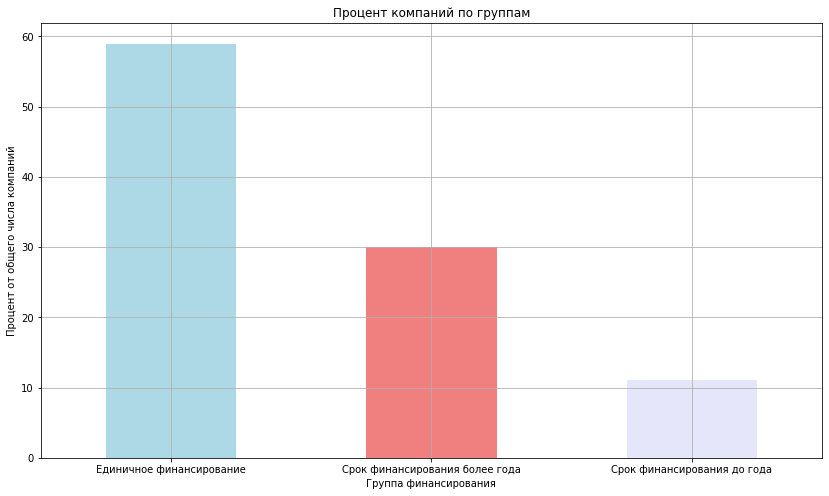

In [21]:
# Считаем проценты
group_counts = df_investments['funding_group'].value_counts()
group_percentages = (group_counts / group_counts.sum()) * 100

plt.figure(figsize=(14, 8))

# Строим столбчатую диаграмму с процентами
group_percentages.plot(
    kind='bar',
    rot=0,
    legend=False,
    title='Процент компаний по группам',
    color=['lightblue', 'lightcoral','lavender']
)

plt.ylabel('Процент от общего числа компаний')
plt.xlabel('Группа финансирования')
plt.grid()
plt.show()

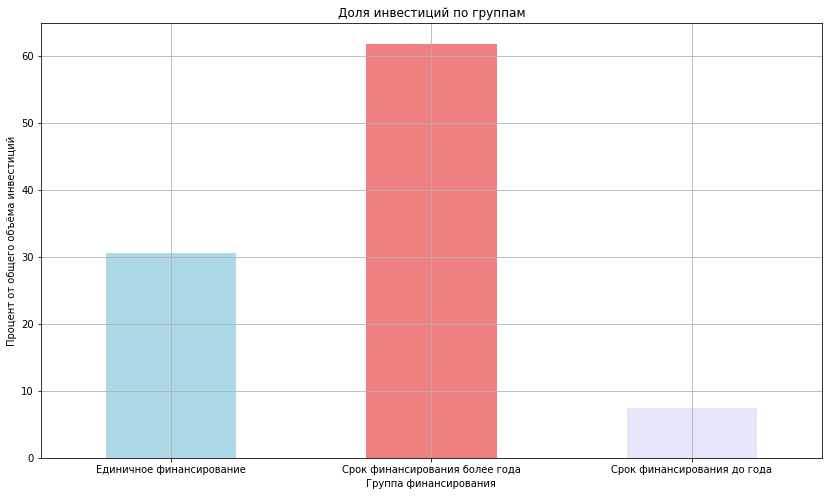

In [22]:
# Сумма инвестиций по группам (доля)
group_funding = df_investments.groupby('funding_group')['funding_total_usd'].sum()
funding_percentages = (group_funding / group_funding.sum()) * 100

plt.figure(figsize=(14, 8))

# Строим столбчатую диаграмму
funding_percentages.plot(
    kind='bar',
    rot=0,
    legend=False,
    title='Доля инвестиций по группам',
    color=['lightblue', 'lightcoral', 'lavender']
)

plt.ylabel('Процент от общего объёма инвестиций')
plt.xlabel('Группа финансирования')
plt.grid()
plt.show()

**Выводы:**

Больше всего компании финансируют единожды но при этом наибольщую долю всех инвестиций забирает долгое финансирование проектов. Это говорит о том что люди, вероятно, либо бросят финансирование проекта после первого вложения, либо будут продолжать его стабильно финансировать в долгой перспективе. 

Скок финансирования до года показывает как самый низкий процент компаний так и самую низкую долю.

### 2.2 Выделение средних и нишевых сегментов рынка

Компании указывают свой сегмент рынка в столбце `market`. Рассчитайте, как часто в датасете встречается каждый из сегментов. Сегменты, к которым относится более 120 компаний, отнесите к массовым, сегменты, в которые входит от 35 до 120 включительно, отнесите к средним, а сегменты до 35 компаний отнесите к нишевым. Рассчитайте, сколько сегментов попадает в каждую из категорий.

Постройте график распределения количества компаний в сегментах и отобразите на нём разделение на нишевые и средние сегменты.

In [23]:
# Подсчитываем количество компаний в каждом сегменте
market_counts = df_investments['market'].value_counts()

# Классифицируем сегменты
def classify_market(count):
    if count > 120:
        return 'массовый'
    elif 35 <= count <= 120:
        return 'средний'
    else:
        return 'нишевый'

market_groups = market_counts.map(classify_market)

# Считаем, сколько сегментов в каждой группе
group_counts = market_groups.value_counts()
print(group_counts)

нишевый     805
средний      81
массовый     54
Name: market, dtype: int64


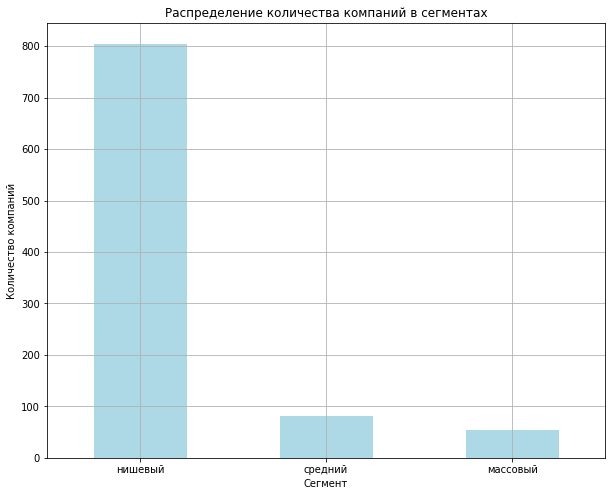

In [24]:
plt.figure(figsize = (10,8))
group_counts.plot( kind = 'bar',
                  rot = 0,
                  legend = False,
                  color = 'lightblue',
                  title = 'Распределение количества компаний в сегментах'
                  
)

plt.ylabel('Количество компаний')
plt.xlabel('Сегмент')
plt.grid()
plt.show()

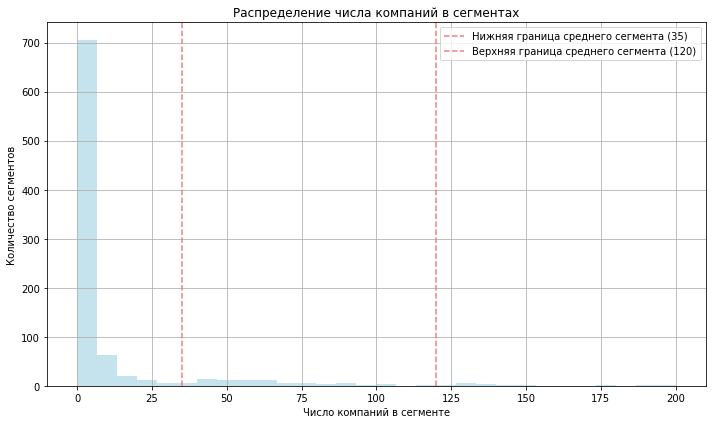

In [25]:
# Считаем число компаний в каждом сегменте 
segment_counts = df_investments.groupby('market')['name'].count()

plt.figure(figsize=(10, 6))

# Гистограмма распределения числа компаний в сегменте
plt.hist(segment_counts.values, 
         bins=30, 
         alpha=0.7, 
         color='lightblue',
         range=(0, 200))  # ← Ограничиваем ось X до 200

plt.axvline(x=35, color='lightcoral', linestyle='--', label='Нижняя граница среднего сегмента (35)')
plt.axvline(x=120, color='lightcoral', linestyle='--', label='Верхняя граница среднего сегмента (120)')

plt.title('Распределение числа компаний в сегментах')
plt.xlabel('Число компаний в сегменте')
plt.ylabel('Количество сегментов')
plt.legend()

plt.grid()
plt.show()

Оставьте в столбце `market` только массовые сегменты. Для остальных сегментов замените значения на заглушки — `niche` для нишевых и `mid` для средних.

Дальнейшие исследования выполняйте с учётом этой замены. Индивидуальные сегменты внутри средней и нишевой групп рассматривать не нужно — они объединяются в два общих сегмента.


In [26]:
# Заменяем значения
market_mapping = {}
for market, classification in market_groups.items():
    if classification == 'массовый':
        market_mapping[market] = market
    elif classification == 'средний':
        market_mapping[market] = 'mid'
    else:  
        market_mapping[market] = 'niche'

df_investments['market'] = df_investments['market'].map(market_mapping)

## Шаг 3. Работа с выбросами и анализ

### 3.1. Анализируем и помечаем выбросы в каждом из сегментов

Заказчика интересует обычный для рассматриваемого периода размер средств, который предоставлялся компаниям.

По предобработанному столбцу `funding_total_usd` графическим образом оцените, какой размер общего финансирования для одной компании будет типичным, а какой — выбивающимся. Укажите интервал, в котором лежат типичные значения.

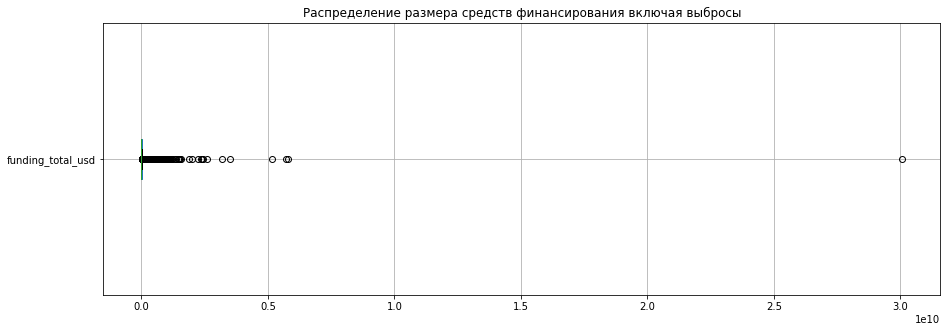

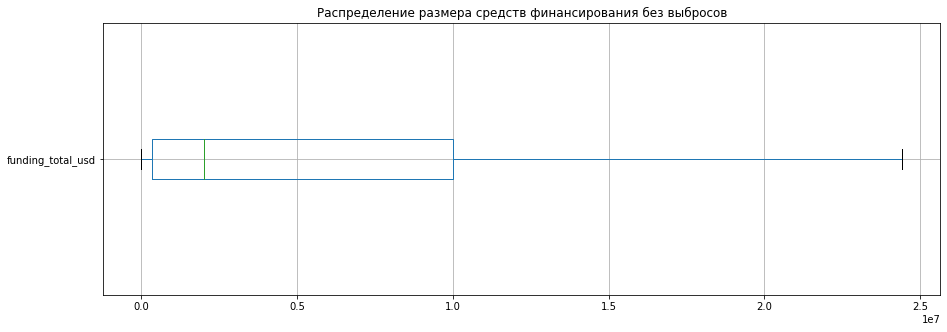

In [27]:
# Смотриим по всему графику
plt.figure(figsize=(15, 5))

df_investments.boxplot(column = 'funding_total_usd', vert=False)

plt.title('Распределение размера средств финансирования включая выбросы')
plt.show()

# Смотриим по графику без аномальных значений
plt.figure(figsize=(15, 5))

df_investments.boxplot(column = 'funding_total_usd', vert=False,showfliers=False)

plt.title('Распределение размера средств финансирования без выбросов')
plt.show()

**Вывод:**

Наблюдается большое количество выбросов с явно больше чем стандартная суммной финансирования тк на графике без выбросов сумма варьируется от 0,15 до 1 с медианным значением 0,25

Определите компании с аномальным объёмом общего финансирования — используйте метод IQR отдельно по каждому сегменту. Напомним, что все нишевые сегменты должны быть объединены в одну группу, а средние — в другую.

Определите сегменты рынка с наибольшей долей компаний, получивших аномальное финансирование, и выведите топ таких сегментов.

In [28]:
# Расчет Q1 и Q3 по всему датасету
q1 = df_investments['funding_total_usd'].quantile(0.25)
q3 = df_investments['funding_total_usd'].quantile(0.75)

iqr = q3 - q1

# Определение границ выбросов
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

# Отфильтровываем и оставляем только аномальные значения 
df_anomalies = df_investments[
    (df_investments['funding_total_usd'] < lower_bound) |
    (df_investments['funding_total_usd'] > upper_bound)
]

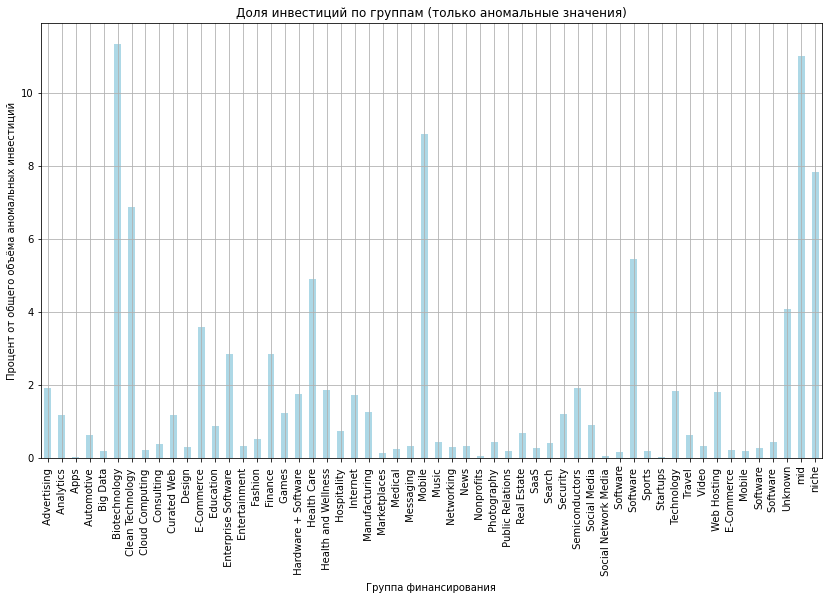

In [29]:

# Сумма инвестиций по группам (доля) на основе аномальных данных
group_funding = df_anomalies.groupby('market')['funding_total_usd'].sum()
funding_percentages = (group_funding / group_funding.sum()) * 100

plt.figure(figsize=(14, 8))

# Визуализируем 
funding_percentages.plot(
    kind='bar',
    legend=False,
    title='Доля инвестиций по группам (только аномальные значения)',
    color = 'lightblue'
)

plt.ylabel('Процент от общего объёма аномальных инвестиций')
plt.xlabel('Группа финансирования')
plt.grid()
plt.show()

In [30]:
# топ-10 компаний по аномальному объему инвестиций 
top_10_anomalies = df_anomalies.sort_values(by = 'funding_total_usd', ascending=False).head(10)

print("Топ 10 компаний с аномальными объёмами инвестиций:")
print(top_10_anomalies[['name', 'funding_total_usd', 'market']])  

Топ 10 компаний с аномальными объёмами инвестиций:
                         name  funding_total_usd                 market
623    Verizon Communications       3.007950e+10                Mobile 
48499                Sberbank       5.800000e+09               Finance 
7074                Clearwire       5.700000e+09              Internet 
1432   Charter Communications       5.162513e+09                Unknown
295    First Data Corporation       3.500000e+09                  niche
47589                   COFCO       3.200000e+09                Unknown
9206                sigmacare       2.600000e+09   Health and Wellness 
8059                 Facebook       2.425700e+09          Social Media 
12693              Carestream       2.400000e+09         Biotechnology 
13528                Flipkart       2.351140e+09                    mid


К сегментам рынка с аномальным финансированием отсосятся: Финансы, Интернет, Биотехнологии, Соц сети а также здоровье и благополучие

In [31]:
df_investments['funding_total_usd'].describe()

count    4.090700e+04
mean     1.591252e+07
std      1.686788e+08
min      1.000000e+00
25%      3.500000e+05
50%      2.000000e+06
75%      1.000000e+07
max      3.007950e+10
Name: funding_total_usd, dtype: float64

Типичным значением для финансирования является 2 миллиона

### 3.2 Определяем границы рассматриваемого периода, отбрасываем аномалии

Проверьте по датасету, можно ли считать, что вам предоставили полные данные за 2014 год. Затем исключите из датасета компании, которые вы ранее посчитали получившими аномальное финансирование.

Когда исключите аномальные записи, на основе столбцов `mid_funding_at` и `funding_rounds` оставьте в датасете данные только об определённых компаниях. Они должны были получать финансирование в годы, когда было зафиксировано 50 или более раундов финансирования.

In [32]:
# Отфильтруем для проверки полноты данных
df_actual = df_investments[
    (df_investments['first_funding_at'] >= '2014-01-01') &
    (df_investments['last_funding_at'] <= '2014-12-31')
]

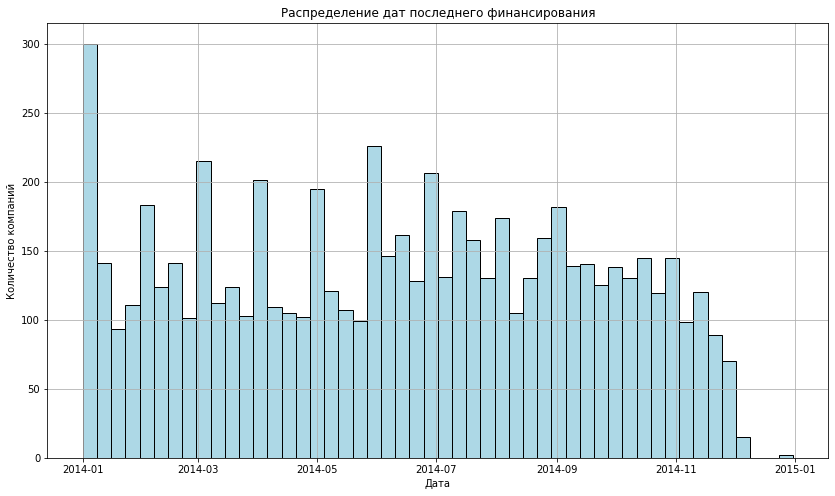

In [33]:
# Визуализируем последние финансирования
plt.figure(figsize=(14, 8))

plt.hist(df_actual['last_funding_at'],
         bins=50, 
         color='lightblue', 
         edgecolor='black')

plt.title('Распределение дат последнего финансирования')
plt.xlabel('Дата')
plt.ylabel('Количество компаний')
plt.xticks(rotation=0)

plt.grid()
plt.show()

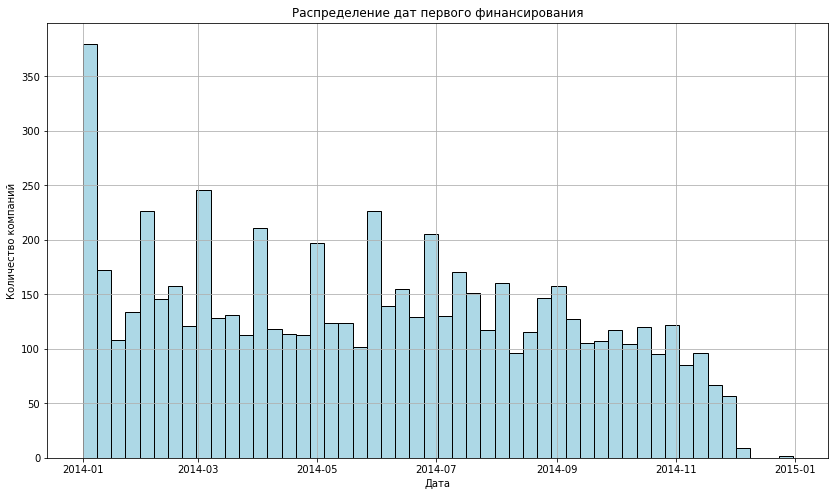

In [34]:
# Визуализируем первое финансирование 
plt.figure(figsize=(14, 8))

plt.hist(df_actual['first_funding_at'],
         bins=50, 
         color='lightblue', 
         edgecolor='black')

plt.title('Распределение дат первого финансирования')
plt.xlabel('Дата')
plt.ylabel('Количество компаний')
plt.xticks(rotation=0)

plt.grid()
plt.show()

Данные за 2014 выглядят полными 

In [35]:
# Исключаем компании с аномальным финансированием 
companies_to_exclude = [
    'Verizon Communications',
    'Sberbank',
    'Clearwire',
    'Charter Communications',
    'First Data Corporation',
    'COFCO',
    'signacare',
    'Facebook',
    'Carestream',
    'Flipkart'
]

df_investments = df_investments[~df_investments['name'].isin(companies_to_exclude)]

In [36]:
# столбец year
df_investments['year'] = df_investments['mid_funding_at'].dt.year

# Считаем общее число раундов по годам
rounds_per_year = df_investments.groupby('year')['funding_rounds'].sum()

# Выбираем годы где суммарно >= 50 раундов
active_years = rounds_per_year[rounds_per_year >= 50].index

# Фильтруем исходный датафрейм: оставляем только компании с годом в active_years
df_filtered = df_investments[df_investments['year'].isin(active_years)]

# удаляем вспомогательную колонку year (на всякий случай)
# df_filtered = df_filtered.drop(columns=['year'])

### 3.3. Анализ типов финансирования по объёму и популярности

Постройте график, который покажет, какие типы финансирования в сумме привлекли больше всего денег. Ориентируйтесь на значения в столбцах `seed`, `venture`, `equity_crowdfunding`, `undisclosed`, `convertible_note`, `debt_financing`, `angel`, `grant`, `private_equity`, `post_ipo_equity`, `post_ipo_debt`, `secondary_market` и `product_crowdfunding`.

Также постройте график, который покажет популярность разных типов финансирования — какие типы финансирования чаще всего используются компаниями, то есть встречаются в датасете наибольшее количество раз.

Сравните графики и выделите часто используемые типы финансирования, которые при этом характеризуются небольшими объёмами, и наоборот — те, что встречаются редко, но при этом характеризуются значительным объёмом предоставленных сумм.

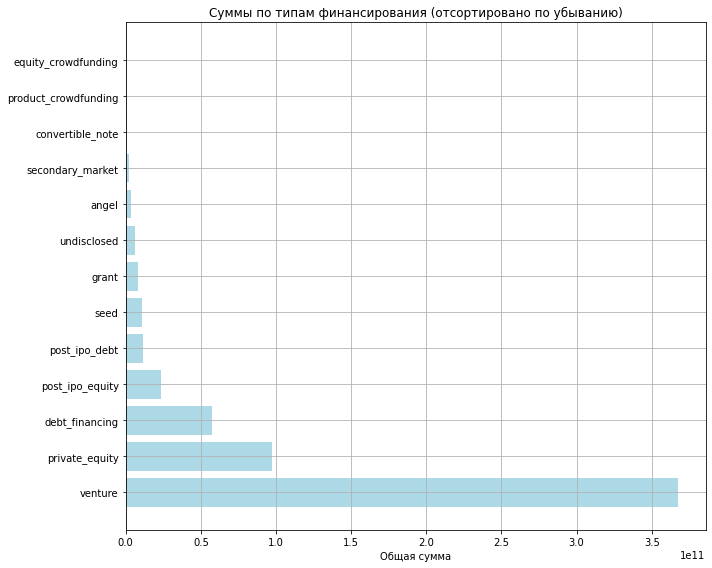

In [37]:
import matplotlib.pyplot as plt

columns = [
    'seed',
    'venture',
    'equity_crowdfunding',
    'undisclosed',
    'convertible_note',
    'debt_financing',
    'angel',
    'grant',
    'private_equity',
    'post_ipo_equity',
    'post_ipo_debt',
    'secondary_market',
    'product_crowdfunding'
]

# Словарь для хранения 
sums = {}

for column in columns:
    sums[column] = df_filtered[column].sum()

# Сортируем 
sorted_sums = dict(sorted(sums.items(), key=lambda item: item[1], reverse=True))

# Визуализируем
plt.figure(figsize=(10, 8))

plt.barh(list(sorted_sums.keys()),
         list(sorted_sums.values()), 
         color='lightblue')

plt.title('Суммы по типам финансирования (отсортировано по убыванию)')
plt.xlabel('Общая сумма')
plt.grid()
plt.tight_layout()
plt.show()

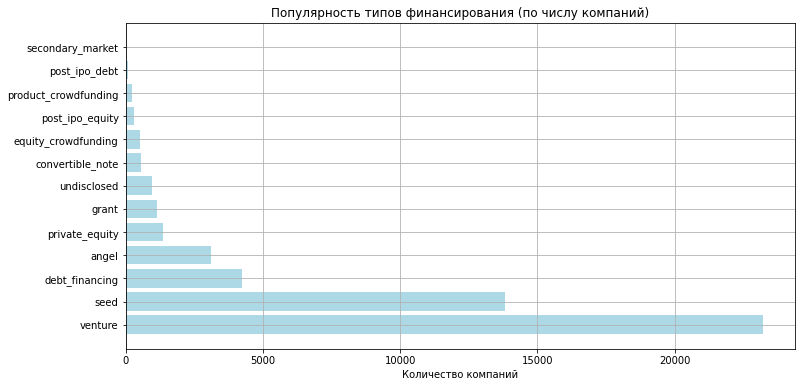

In [38]:
# Считаем сколько раз значение != 0
counts = {}
for column in columns:
    counts[column] = (df_filtered[column] > 0).sum()

# Сортируем 
sorted_counts = dict(sorted(counts.items(), key=lambda item: item[1], reverse=True))

# Визуализация
plt.figure(figsize=(12, 6))
plt.barh(list(sorted_counts.keys()),
         list(sorted_counts.values()),
         color='lightblue')

plt.title('Популярность типов финансирования (по числу компаний)')
plt.xlabel('Количество компаний')

plt.grid()
plt.show()

**Выводы:**

**Наиболее прибыльными оказались:**

1. Венчурные инвестиции (сильно превышают объемом все остальные)
2. Инвестиции в виде прямых (частных) вложений
3. Долговое финансирование 
4. Финансирование после IPO 
5. Долговое финансирование после IPO и инвестиции на посевной стадии

Остальные типы финансирования оказались не такими объемными по вложениям

**Наиболее популярным видом финансирования являются:**
1. Венчурные инвестиции
2. Инвестиции на посевной стадии
3. Долговое финансирование  
4. бизнес-ангелы 
5. Инвестиции в виде прямых (частных) вложений

Общий вывод: Самыми популярными и прибыльными являются Венчурные инвестиции, но при этоп, далее топ популярных и прибыльных типов финансирования не совсем совпадает. Можно сделать вывод, что популярные типы финансирования не всегда будут прибыльными


Постройте график суммарных объёмов возвратов от разных типов финансирования за весь период на основе дополнительного датасета.

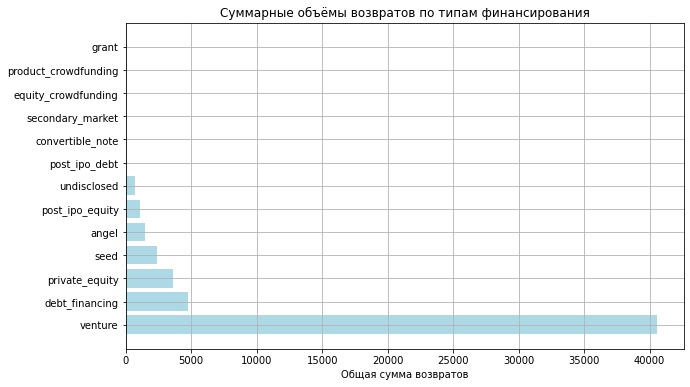

In [39]:
# Типы возвратов
columns = [
    'seed',
    'venture',
    'equity_crowdfunding',
    'undisclosed',
    'convertible_note',
    'debt_financing',
    'angel',
    'grant',
    'private_equity',
    'post_ipo_equity',
    'post_ipo_debt',
    'secondary_market',
    'product_crowdfunding'
]

sums = {}
for column in columns:
    sums[column] = df_returns[column].sum()

# Сортируем 
sorted_sums = dict(sorted(sums.items(), key=lambda item: item[1], reverse=True))

# Визуализация
plt.figure(figsize=(10, 6))

plt.barh(list(sorted_sums.keys()), 
         list(sorted_sums.values()), 
         color='lightblue')

plt.title('Суммарные объёмы возвратов по типам финансирования')
plt.xlabel('Общая сумма возвратов')

plt.grid()
plt.show()

Возвратов больше всего также по венчурным инвестициям

## Шаг 4. Анализ динамики

### 4.1 Динамика предоставления финансирования по годам

Используя столбцы `funding_total_usd` и `funding_rounds`, рассчитайте для каждой компании средний объём одного раунда финансирования.

На основе получившейся таблицы постройте графики, отражающие:
* динамику типичного размера средств, которые стартапы получали в рамках одного раунда финансирования;

* динамику общего количества раундов за каждый год, то есть насколько активно происходили инвестиции на рынке (чем больше раундов, тем выше активность).

Когда будете строить графики в этом задании и следующих, используйте данные только по тем компаниям, которые остались в датасете после предыдущих фильтраций.

На основе полученных данных ответьте на вопросы:
* В каком году типичный размер средств, собранных в рамках одного раунда, был максимальным?

* Какая тенденция наблюдалась в 2014 году по количеству раундов и средств, выделяемых в рамках каждого раунда?

In [40]:
avg_funding = df_filtered['funding_total_usd']/df_filtered['funding_rounds']

# добавляем нужный столбец
df_filtered['avg_funding'] = avg_funding

/tmp/ipykernel_150/3182194351.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['avg_funding'] = avg_funding


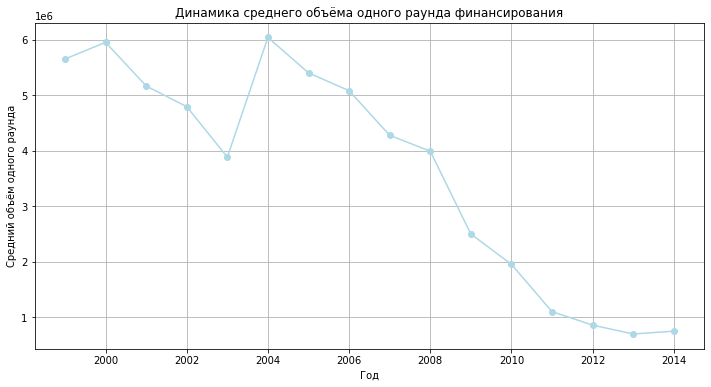

In [41]:
# Группируем по году и считаем 
yearly_avg = df_filtered.groupby('year')['avg_funding'].median()

plt.figure(figsize=(12, 6))

plt.plot(yearly_avg.index.to_numpy(), 
         yearly_avg.to_numpy(), 
         marker='o', 
         linestyle='-', 
         color='lightblue')

plt.title('Динамика среднего объёма одного раунда финансирования')
plt.xlabel('Год')
plt.ylabel('Средний объём одного раунда')

plt.grid()
plt.show()

Типичный размер средств, собранных в рамках одного раунда был максимальным в 1999 году, также высокие показатели наблюдаются на 2002 года. Не считая падений в 2003 и 2013 годах, далее наблюдается средний уровень

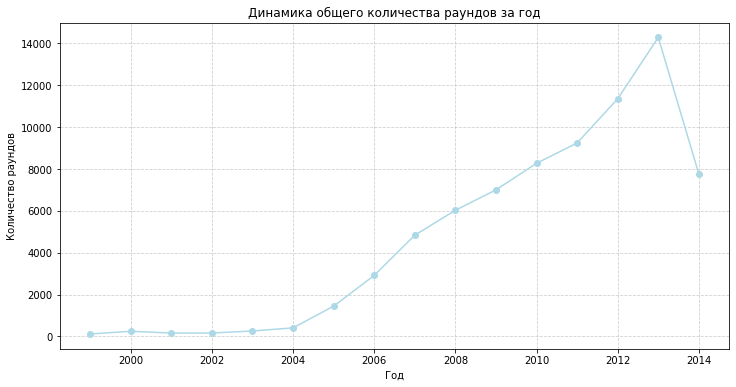

In [42]:
# Группируем по году и считаем сумму раундов
round_sum = df_filtered.groupby('year')['funding_rounds'].sum()

plt.figure(figsize=(12, 6))

plt.plot(round_sum.index.to_numpy(), 
         round_sum.to_numpy(), 
         marker='o', 
         linestyle='-', 
         color='lightblue')

plt.title('Динамика общего количества раундов за год')
plt.xlabel('Год')
plt.ylabel('Количество раундов')

plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Наблюдается стремительный рост количества раундов до 2013, затем сильный спад в 2014 на уровень 2010 года

### 4.2 Динамика размера общего финансирования по массовым сегментам рынка для растущих в 2014 году сегментов

Составьте сводную таблицу, в которой указывается суммарный размер общего финансирования `funding_total_usd` по годам и сегментам рынка. Отберите из неё только те сегменты, которые показывали рост размера суммарного финансирования в 2014 году по сравнению с 2013.

На графике отразите, как менялся суммарный размер общего финансирования в каждом из отобранных сегментов по годам, за которые у вас достаточно данных. Рассматривайте только массовые сегменты, а средние и нишевые исключите.

На основе графика сделайте вывод о том, какие сегменты показывают наиболее быстрый и уверенный рост.

In [43]:
# Фильтруем датафрейм по годам
df_filtered_years = df_investments[
    (df_investments['year'] >= 2013) & 
    (df_investments['year'] <= 2014)
]

pivot = df_filtered_years.pivot_table(
    values='funding_total_usd',
    index='year',
    columns='market',
    aggfunc='sum',
    fill_value=0
)

print(pivot)

market   Advertising    Analytics       Apps    Automotive    Big Data   \
year                                                                      
2013.0      748883456    885374272  112024008     171677632   180998928   
2014.0      302324288    194973952  201387168      57452760   118967000   

market   Biotechnology    Clean Technology    Cloud Computing    Consulting   \
year                                                                           
2013.0       9882970112          4653555712          176284240     450562656   
2014.0       3967731200          1934029824           68865856     480267136   

market   Curated Web   ...    Travel      Video    Web Hosting   E-Commerce   \
year                   ...                                                     
2013.0     1556695552  ...  998041536  168576048     1385825792    454107744   
2014.0      559607296  ...  279432288  665974912      578998464     40030552   

market    Mobile    Software  Software      Unknown      

Возрасли такие отрасли как Video, Consulting и Apps, у остальных размер финансирования сократился

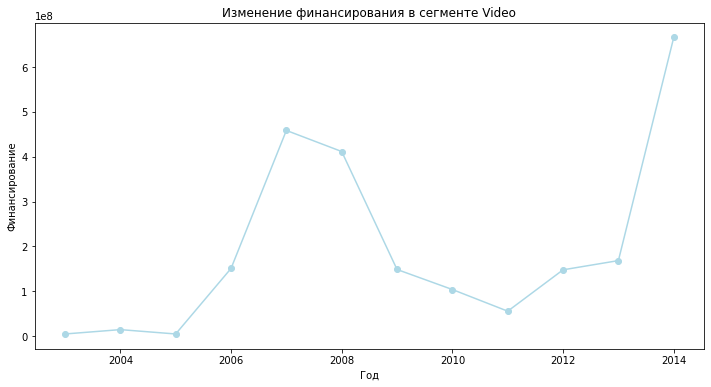

In [44]:
plt.figure(figsize=(12, 6))

df_video = df_investments[df_investments['market'] == ' Video ']
video_funding = df_video.groupby('year')['funding_total_usd'].sum()

plt.plot(video_funding.index.to_numpy(), 
         video_funding.to_numpy(),
         marker='o', 
         color='lightblue'
        )

plt.title('Изменение финансирования в сегменте Video')
plt.xlabel('Год')
plt.ylabel('Финансирование')
plt.show()

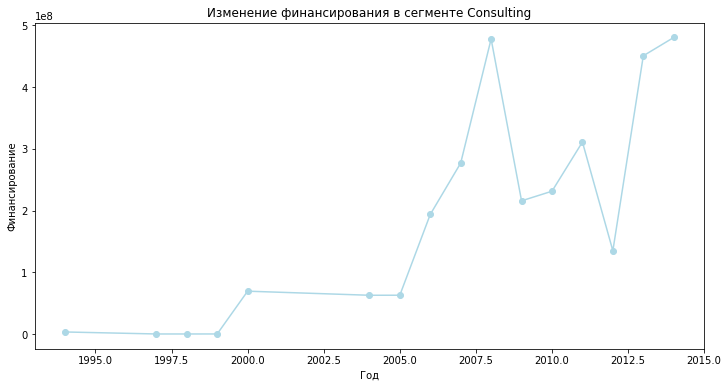

In [45]:
plt.figure(figsize=(12, 6))

df_consulting = df_investments[df_investments['market'] == ' Consulting ']
consulting_funding = df_consulting.groupby('year')['funding_total_usd'].sum()

plt.plot(consulting_funding.index.to_numpy(), 
         consulting_funding.to_numpy(),
         marker='o', 
         color='lightblue'
        )

plt.title('Изменение финансирования в сегменте Consulting')
plt.xlabel('Год')
plt.ylabel('Финансирование')
plt.show()

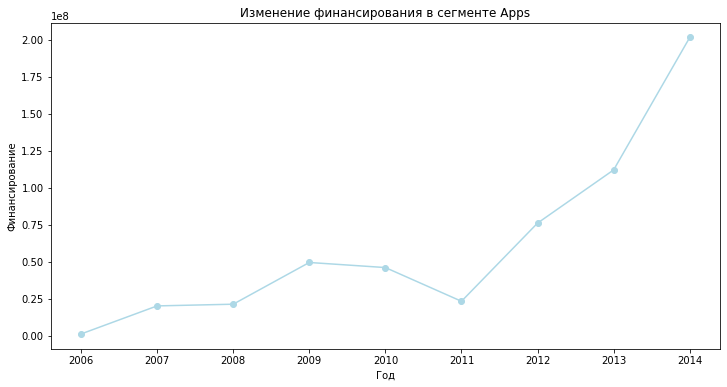

In [46]:
plt.figure(figsize=(12, 6))

df_apps = df_investments[df_investments['market'] == ' Apps ']
apps_funding = df_apps.groupby('year')['funding_total_usd'].sum()

plt.plot(apps_funding.index.to_numpy(), 
         apps_funding.to_numpy(),
         marker='o', 
         color='lightblue'
        )

plt.title('Изменение финансирования в сегменте Apps')
plt.xlabel('Год')
plt.ylabel('Финансирование')
plt.show()

Самый стремительный рост наблюдается у Video, далее Apps и затем скачками Consulting

### 4.3 Годовая динамика доли возвращённых средств по типам финансирования

Заказчик хочет знать, какая часть вложенных или выданных денег со временем возвращается обратно инвесторам или финансистам. Ваша цель — для каждого года и каждого вида финансирования рассчитать нормированные значения возврата средств: то есть какую долю возвращённые средства составляют от предоставленных. При этом слишком большие аномальные значения, то есть неадекватные выбросы, нужно заменить на пропуски.

Совет: когда будете делить сумму возвращённых средств на суммарный объём привлечённого финансирования по конкретному году, добавьте к знаменателю небольшое число, например `1e-60`. Это поможет избежать деления на ноль.

In [47]:
# Суммарный объём вложений 
investment_totals = df_investments.groupby('year')[
    'seed', 'venture', 'equity_crowdfunding', 'undisclosed', 'convertible_note',
    'debt_financing', 'angel', 'grant', 'private_equity', 'post_ipo_equity',
    'post_ipo_debt', 'secondary_market', 'product_crowdfunding'
].sum()

# Возвраты
returns_totals = df_returns[
    ['seed', 'venture', 'equity_crowdfunding', 'undisclosed', 'convertible_note',
     'debt_financing', 'angel', 'grant', 'private_equity', 'post_ipo_equity',
     'post_ipo_debt', 'secondary_market', 'product_crowdfunding']
]

# возврат / (вложение + 1e-60)
ratio = returns_totals / (investment_totals + 1e-60)
print(ratio)

                seed       venture  equity_crowdfunding   undisclosed  \
year                                                                    
1921.0           NaN           NaN                  NaN           NaN   
1960.0           NaN           NaN                  NaN           NaN   
1979.0           NaN           NaN                  NaN           NaN   
1982.0           NaN           NaN                  NaN           NaN   
1983.0           NaN           NaN                  NaN           NaN   
1984.0           NaN           NaN                  NaN           NaN   
1985.0           NaN           NaN                  NaN           NaN   
1987.0           NaN           NaN                  NaN           NaN   
1989.0           NaN           NaN                  NaN           NaN   
1990.0           NaN           NaN                  NaN           NaN   
1992.0           NaN           NaN                  NaN           NaN   
1993.0           NaN           NaN                 

/tmp/ipykernel_150/4124969687.py:2: FutureWarning: Indexing with multiple keys (implicitly converted to a tuple of keys) will be deprecated, use a list instead.
  investment_totals = df_investments.groupby('year')[


Постройте график, на котором отобразите нормированные значения возврата средств для типов финансирования `venture`, `debt_financing`, `private_equity`, `seed` и `angel`.

Сделайте вывод о том, в каких типах финансирования наблюдается наиболее устойчивый рост показателя.

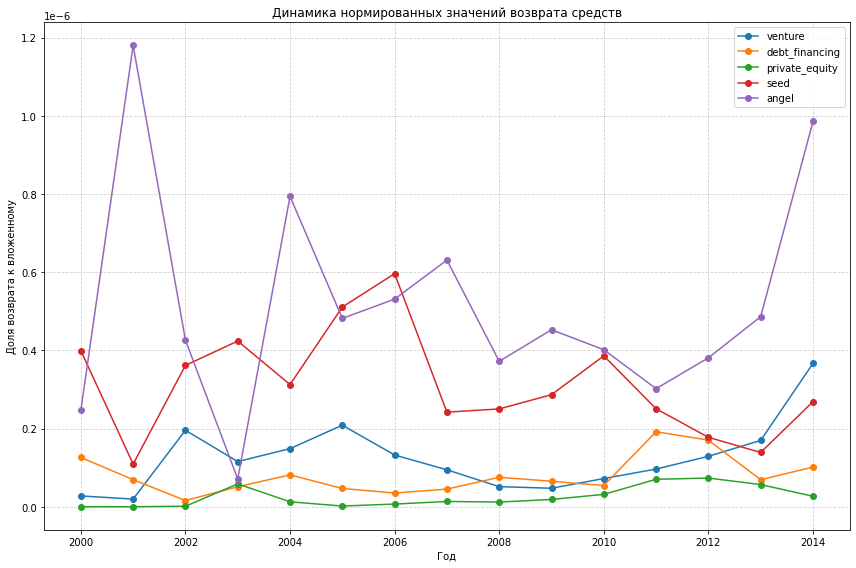

In [48]:
ratio_cleaned = ratio.copy() # копия чтоб не менять оригинал
selected_types = ['venture', 'debt_financing', 'private_equity', 'seed', 'angel']

# Фильтруем датафрейм
subset = ratio_cleaned[selected_types]

# Построение графика
plt.figure(figsize=(12, 8))

for col in subset.columns:
    plt.plot(subset.index, 
             subset[col], 
             label=col, 
             marker='o'
            )

plt.title('Динамика нормированных значений возврата средств')
plt.xlabel('Год')
plt.ylabel('Доля возврата к вложенному')
plt.legend()

plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

Самый высокий рост, но и самые сильные скачки у angel, дальше идёт seed с некоторым снижением показателей после 2010 года. Самый стабильный постепенный рост наблюдается у venture


## Шаг 5. Итоговый вывод и рекомендации

Представьте, что на календаре 2015 год. Опираясь на результаты анализа, дайте рекомендацию заказчику:

* в какую отрасль стоит инвестировать;
* какой тип финансирования при этом будет наиболее уместным.

Подведите итоги проекта:
* опишите, какие шаги были выполнены;
* какие выводы удалось сделать;
* насколько выводы согласуются между собой или, наоборот, вызывают сомнения.



**Рекомендации:**
1. Биотехнологии, чистые технологии и мобильные технологии являются наиболее перспективными отраслями для инвестиций, тк привлекают наибольшие (даже аномальные) объёмы финансирования
2. Наиболее эффективными типами финансирования являются венчурные инвестиции и прямые (частные) вложения, тк они обеспечивают высокую отдачу и стабильный рост возвратов средств. Эти типы финансирования сочетают в себе высокую популярность, объёмы вложений и потенциал роста, что делает их оптимальным выбором для инвесторов

**Итоги:**
1. Проведена предобработка данных, были убраны дубликаты и пропуски, а также проверена корректность числовых и временных значений
2. Выделены группы компаний по срокам финансирования, после чего они были сравнены по количеству и объёму инвестиций
3. Сегменты рынка были классифицированы на массовые, средние и нишевые, и эти категории были учтены в дальнейшем анализе
4. Определены типичные и аномальные значения объёмов финансирования, выбросы были исключены, а период исследования ограничен
5. Проведено сравнение популярности и объёмов разных типов финансирования
6. Проанализирована динамика раундов и объёмов инвестиций по годам, а также выявлены изменения в массовых сегментах рынка
7. Рассчитана доля возврата средств для разных типов финансирования, после чего была оценена её устойчивость
8. Подведены  выводы, на основе которых даны рекомендации
